In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
x_raw = np.arange(1, 11)
# y = np.array([1,1,1,1,1,0,0,0,0,0])   # step  -> fits with 2 neurons
# y = np.array([0,0,0,1,1,1,1,0,0,0])   # bump  -> fits with 2 neurons
y = np.array([1,1,0,1,0,1,1,0,0,1])     # alternating -> needs many neurons (32 is reliable)

# Standardize the input (mean 0, std 1) so the softplus neurons work in their curved region
x = (x_raw - x_raw.mean()) / x_raw.std()

N_HIDDEN = 32   # number of neurons in the hidden layer

<Axes: >

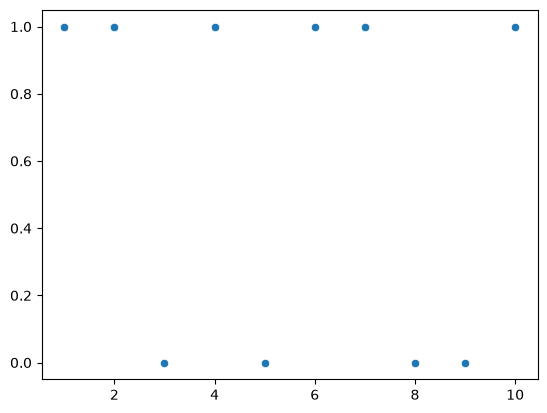

In [3]:
sns.scatterplot(x=x_raw, y=y)

## Network

```
x ──► z = x·W + B ──► h = softplus(z) ──► y_hat = sigmoid(h·V + c)
       (N values)       (N values)            (1 value)
```

Parameters (all neurons at once, as arrays):
- `W`, `B`: input → hidden weights and biases, shape `(N,)`
- `V`: hidden → output weights, shape `(N,)`
- `c`: output bias (a single number)

For a batch of `n` samples, `Z` and `H` have shape `(n, N)`: one row per sample, one column per neuron.

In [4]:
W, B, V, c = None, None, None, 0.0
Z, H = None, None   # cached from the forward pass, needed by backprop

In [5]:
def cal_sigmoid(z):
    return 1 / (1 + np.exp(-z))

def cal_softplus(z):
    return np.logaddexp(0, z)   # = log(1 + e^z), but never overflows

In [6]:
def cal_loss(y, y_hat):
    # Binary cross-entropy, averaged over samples
    y_hat = np.clip(y_hat, 1e-12, 1 - 1e-12)   # avoid log(0)
    return np.mean(-(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat)))

In [7]:
def cal_z(x, W, B):
    # (n,) outer (N,) -> (n, N): every sample through every neuron
    return np.outer(x, W) + B

def cal_input_to_layer1(x):
    z = cal_z(x, W, B)
    return z, cal_softplus(z)

def cal_layer1_to_output(H):
    # (n, N) @ (N,) -> (n,)
    return cal_sigmoid(H @ V + c)

def cal_forward_propagation(x):
    _, h = cal_input_to_layer1(np.atleast_1d(x))
    return cal_layer1_to_output(h)

## Chain rule pieces

Same pieces as the 2-neuron version, now for all neurons at once:

- `dL/d(output before sigmoid) = y_hat - y` (sigmoid + cross-entropy simplify to this)
- `d(output)/dV = h`, `d(output)/dc = 1`, `d(output)/dh = V`
- `dh/dz = sigmoid(z)` (derivative of softplus)
- `dz/dW = x`, `dz/dB = 1`

In [8]:
def dL_to_dy(y, y_hat):
    return y_hat - y                 # (n,)

def dy_to_dh(V):
    return V                         # (N,)

def dy_to_dv(H):
    return H                         # (n, N)

def dh_to_dz(Z):
    return cal_sigmoid(Z)            # (n, N)

def dz_to_dw(x):
    return x[:, None]                # (n, 1), broadcasts across neurons

In [9]:
def gradients(x, y, y_hat):
    dy = dL_to_dy(y, y_hat)[:, None]                 # (n, 1)
    dz = dy * dy_to_dh(V) * dh_to_dz(Z)              # (n, N): error arriving at each neuron's z

    grad_W = np.mean(dz * dz_to_dw(x), axis=0)       # (N,)
    grad_B = np.mean(dz, axis=0)                     # (N,)
    grad_V = np.mean(dy * dy_to_dv(H), axis=0)       # (N,)
    grad_c = np.mean(dy)                             # scalar
    return grad_W, grad_B, grad_V, grad_c

In [10]:
def init():
    global W, B, V, c
    # wide random init spreads the neurons' bends across the x range
    W = np.random.randn(N_HIDDEN) * 3
    B = np.random.randn(N_HIDDEN) * 3
    V = np.random.randn(N_HIDDEN)
    c = 0.0

In [11]:
def forward_propagation(x, y):
    global Z, H
    Z, H = cal_input_to_layer1(x)
    predictions = cal_layer1_to_output(H)
    return cal_loss(y, predictions), predictions

In [12]:
def back_propagation(predictions):
    global W, B, V, c
    grad_W, grad_B, grad_V, grad_c = gradients(x, y, predictions)
    W -= lr * grad_W
    B -= lr * grad_B
    V -= lr * grad_V
    c -= lr * grad_c

In [13]:
def fit(x, y):
    init()
    loss = []

    for i in range(n_iters):
        l, predictions = forward_propagation(x, y)
        loss.append(l)
        back_propagation(predictions)

    l, predictions = forward_propagation(x, y)   # predictions with the final weights
    loss.append(l)
    return loss, predictions


final loss: 0.0008889778016782382
predictions: [1.    1.    0.002 0.997 0.002 0.999 1.    0.    0.    1.   ]
exact fit: True


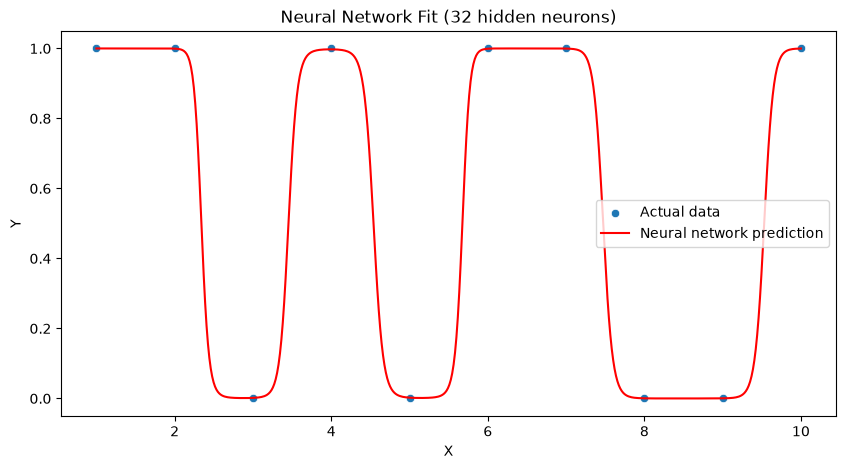

In [14]:
lr = 0.5
n_iters = 20000

loss, predictions = fit(x, y)
print('final loss:', loss[-1])
print('predictions:', predictions.round(3))
print('exact fit:', np.array_equal(predictions.round(), y))

# smooth curve of the learned function between the data points
x_plot = np.linspace(x_raw.min(), x_raw.max(), 500)
y_plot = cal_forward_propagation((x_plot - x_raw.mean()) / x_raw.std())

plt.figure(figsize=(10, 5))

sns.scatterplot(x=x_raw, y=y, label='Actual data')
plt.plot(x_plot, y_plot, color='red', label='Neural network prediction')

plt.xlabel('X')
plt.ylabel('Y')
plt.title(f'Neural Network Fit ({N_HIDDEN} hidden neurons)')
plt.legend()
plt.show()

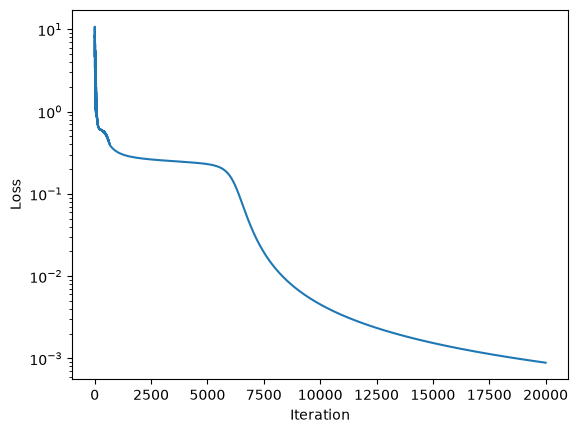

In [15]:
plt.plot(loss)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.yscale('log')
plt.show()